# Plate Reader Data Analysis: Fluorescence

1) CD1 - Conrad's first run of the experimental protocol (2025-05-13)
2) CD2 - Conrad's second run of the experimental protocol (2025-05-28)
3) AL1 - my first run of the experimental protocol (2025-10-21)


## Setup


In [ ]:
## SHARED CONFIG ##

# Reload configs on each run.
import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (CIRCUIT_WELLS, FIGURE_DPI, PDF_DPI, POLY_ORDER, REPLICATES,
                               SAMPLING_METHOD, TAGS, WELLS, biomass_and_floor, blank_series,
                               load_plate_series, smooth, usable_blank_wells)


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bioutils import transform


## PLOTTING ##

plt.rcParams["figure.dpi"] = FIGURE_DPI
plt.rcParams["savefig.dpi"] = FIGURE_DPI


## OUTPUT ##

# csv + pdf output
OUT_DIR = Path("out")
OUT_DIR.mkdir(exist_ok=True)

# 92-page render takes minutes
GENERATE_PDF = True

# Low dpi keeps the 92-page render fast


## CIRCUITS ##

# Circuit shown in the inline figures
CIRCUIT = 10


## DETECTION FLOOR ##

## OD CURVE ##



# Circuits + controls
ALL_GROUPS = {
    **{f"Circuit {circuit}": (CIRCUIT_WELLS[circuit], "black") for circuit in range(1, 93)},
    "pRPU": (WELLS["pRPU"], "purple"),
    "pL2":  (WELLS["pL2"],  "orange"),
    "WT":   (WELLS["wt"],   "navy"),
}

# Subset drawn inline
GROUPS = {name: ALL_GROUPS[name] for name in (f"Circuit {CIRCUIT}", "pRPU", "WT")}


In [2]:
# Load data
od_raw, fl_raw, t_minutes = load_plate_series()

for tag in TAGS:
    print(f"{tag}: plate shape={od_raw[tag].shape}, runtime={t_minutes[tag][-1]:.0f} min")


Rep1: plate shape=(16, 24, 41), runtime=480 min
Rep2: plate shape=(16, 24, 41), runtime=480 min
Rep3: plate shape=(16, 24, 41), runtime=480 min


## Blank Fluorescence Distribution

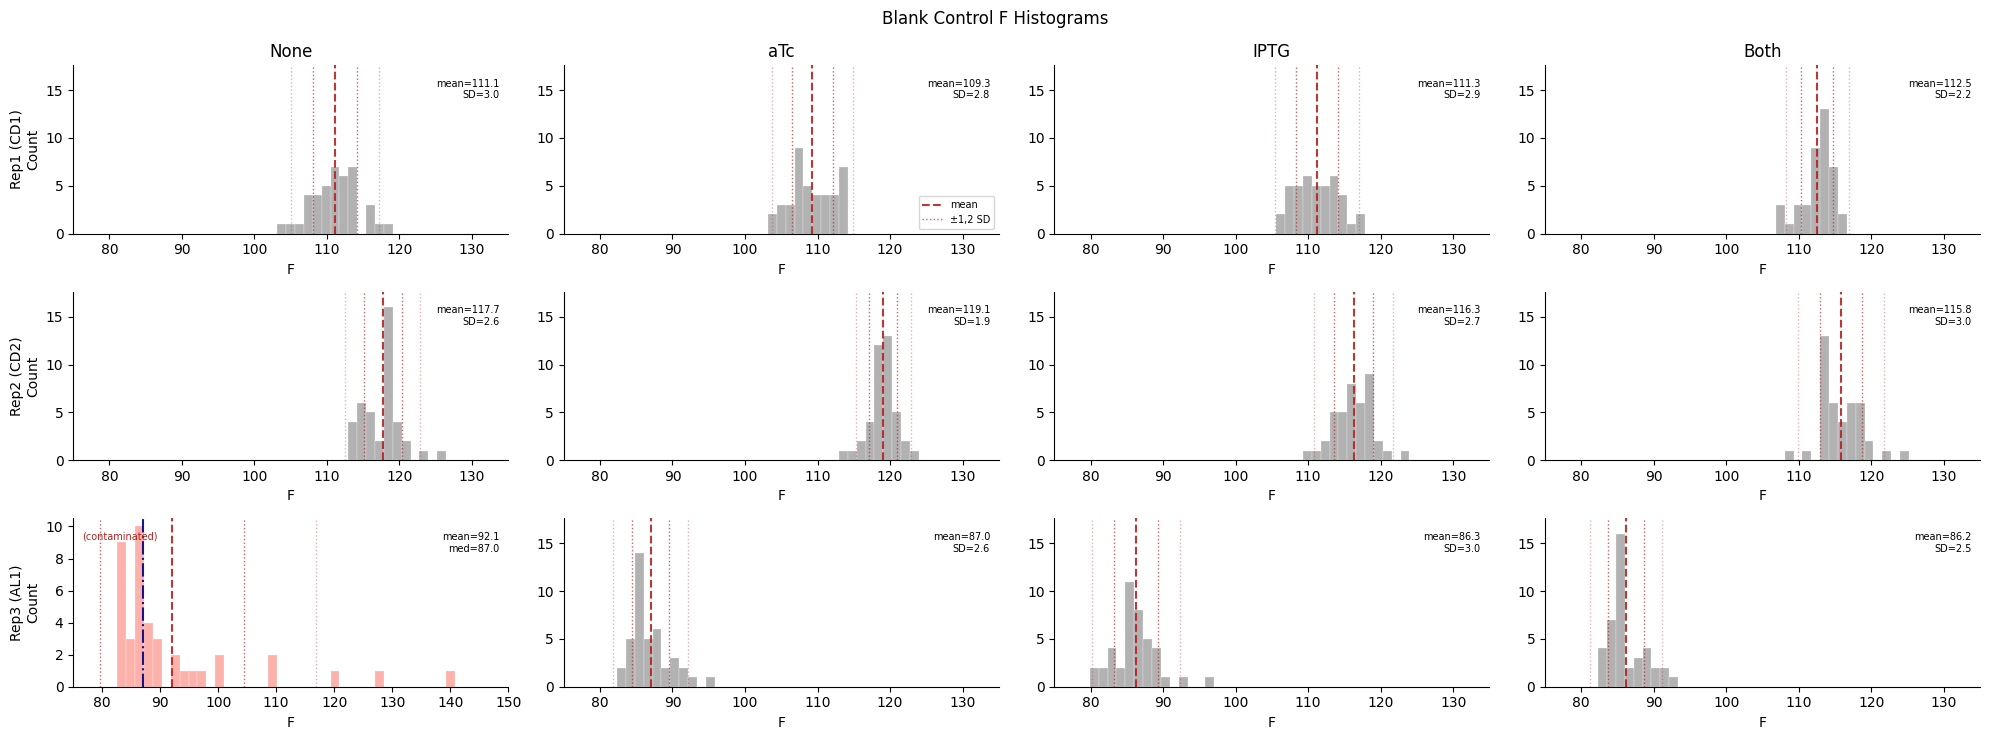

In [4]:
# Raw blank F histogram per (replicate, condition)
BLANK_FL_HISTOGRAM_BINS = np.linspace(75, 135, 50)
BLANK_FL_EXCLUDED_HISTOGRAM_BINS = np.linspace(75, 150, 50)

fig, axes = plt.subplots(len(REPLICATES), 4, figsize=(20, 7.5))
shared_axes, ymax = [], 0
for rep_i, rep in enumerate(REPLICATES):
    tag = rep["tag"]
    rows, cols = zip(*rep["wells"]["blank"])
    # [4 cond, n_t]
    blank = fl_raw[tag][list(rows), list(cols), :].astype(float)

    for well in range(4):
        ax = axes[rep_i, well]
        vals = blank[well][np.isfinite(blank[well])]

        # Contaminated blank is plate-specific
        is_excluded = well not in usable_blank_wells(4, rep["label"])

        is_legend_panel = rep_i == 0 and well == 1
        mean, median, sd = vals.mean(), np.median(vals), vals.std()

        bins = BLANK_FL_EXCLUDED_HISTOGRAM_BINS if is_excluded else BLANK_FL_HISTOGRAM_BINS
        counts, _, _ = ax.hist(vals, bins=bins, color=("salmon" if is_excluded else "gray"),
                               alpha=0.6, edgecolor="white", linewidth=0.3)

        ax.axvline(mean, color="firebrick", ls="--", lw=1.5, alpha=0.9,
                   label="mean" if is_legend_panel else None)

        if is_excluded:
            ax.axvline(median, color="navy", ls="-.", lw=1.5, alpha=0.9,
                       label="median" if is_legend_panel else None)

        for i, (n_sd, alpha) in enumerate([(1, 0.7), (2, 0.35)]):
            ax.axvline(mean - n_sd * sd, color="firebrick", ls=":", lw=1, alpha=alpha,
                       label="\u00b11,2 SD" if is_legend_panel and i == 0 else None)
            ax.axvline(mean + n_sd * sd, color="firebrick", ls=":", lw=1, alpha=alpha)

        stats = (f"mean={mean:.1f}\nmed={median:.1f}" if is_excluded
                 else f"mean={mean:.1f}\nSD={sd:.1f}")
        ax.text(0.98, 0.92, stats, transform=ax.transAxes, ha="right", va="top", fontsize=7)

        if is_excluded:
            ax.text(0.02, 0.92, "(contaminated)", transform=ax.transAxes,
                    ha="left", va="top", fontsize=7, color="firebrick")
            ax.set_xlim(75, 150)
        else:
            shared_axes.append(ax)
            ymax = max(ymax, counts.max())
            ax.set_xlim(75, 135)

        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        ax.set_xlabel("F")
        if rep_i == 0:
            ax.set_title(rep["cond_labels"][well])
        if well == 0:
            ax.set_ylabel(f"{tag} ({rep['label']})\nCount")

for ax in shared_axes:
    ax.set_ylim(0, ymax * 1.1)

axes[0, 1].legend(fontsize=7, loc="lower right")
fig.suptitle("Blank Control F Histograms")
plt.tight_layout()
plt.show()

## Blank Fluorescence Over Time

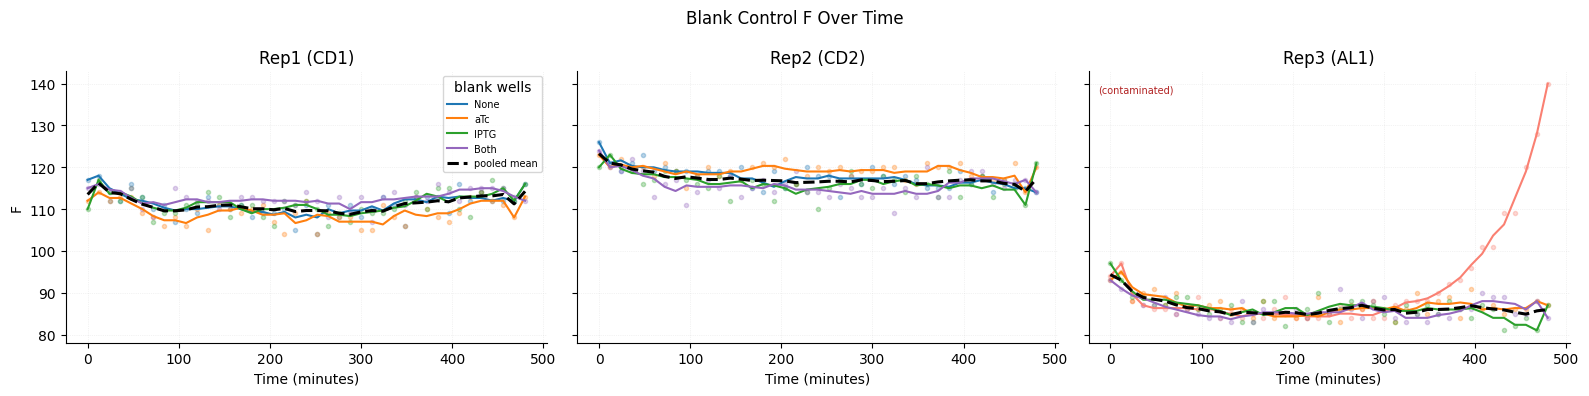

In [5]:
# Raw blank F over time, one line per condition
# Linear y: the drift is the subject
BLANK_CONDITION_COLOURS = ("tab:blue", "tab:orange", "tab:green", "tab:purple")

fig, axes = plt.subplots(1, len(REPLICATES), figsize=(16, 4), sharey=True)
for rep_i, rep in enumerate(REPLICATES):
    tag = rep["tag"]
    ax = axes[rep_i]
    rows, cols = zip(*rep["wells"]["blank"])
    # [4 cond, n_t]
    blank = fl_raw[tag][list(rows), list(cols), :].astype(float)
    blank_smooth = smooth(fl_raw[tag][list(rows), list(cols), :])

    usable = usable_blank_wells(4, rep["label"])

    for well in range(4):
        # Contaminated blank is plate-specific
        is_excluded = well not in usable
        colour = "salmon" if is_excluded else BLANK_CONDITION_COLOURS[well]

        ax.plot(t_minutes[tag], blank[well], "o", color=colour, ms=3, alpha=0.3, zorder=1)
        ax.plot(t_minutes[tag], blank_smooth[well], color=colour, lw=1.5, zorder=2,
                label=rep["cond_labels"][well] if rep_i == 0 else None)

        if is_excluded:
            ax.text(0.02, 0.95, "(contaminated)", transform=ax.transAxes,
                    ha="left", va="top", fontsize=7, color="firebrick")

    # the pool the subtraction takes off F
    ax.plot(t_minutes[tag], blank_smooth[usable].mean(axis=0), color="black", lw=2.2,
            ls="--", zorder=3, label="pooled mean" if rep_i == 0 else None)

    ax.grid(True, alpha=0.3, linewidth=0.5, ls=":")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.set_xlabel("Time (minutes)")
    ax.set_title(f"{tag} ({rep['label']})")
    if rep_i == 0:
        ax.set_ylabel("F")
        ax.legend(fontsize=7, title="blank wells")

fig.suptitle("Blank Control F Over Time")
plt.tight_layout()
plt.show()

In [6]:
## DETECTION THRESHOLD ##

# Pooled blank and detection threshold per plate
POOLED_BLANK, DETECTION_THRESHOLD, POOLED_BLANK_FL = blank_series(od_raw, fl_raw)


In [7]:
# Subtract the plate's pooled blank from OD and from F.

biomass, fl_no_bg, above_floor = {}, {}, {}

for name, (wells, colour) in ALL_GROUPS.items():
    biomass[name], fl_no_bg[name], above_floor[name] = {}, {}, {}
    for rep in REPLICATES:
        tag = rep["tag"]
        rows, cols = zip(*wells)

        # smoothed, pooled-blank-corrected, and the floor tested on that same series
        biomass[name][tag], above_floor[name][tag] = biomass_and_floor(
            od_raw[tag][list(rows), list(cols), :], POOLED_BLANK[tag],
            DETECTION_THRESHOLD[tag])
        # F smoothed before the blank comes off, as OD is
        fl_no_bg[name][tag] = (smooth(fl_raw[tag][list(rows), list(cols), :])
                               - POOLED_BLANK_FL[tag])


In [8]:
# Method 1 polyfit of ln(B), as in analyse_pr_biomass.ipynb

ln_od_fit = {}
for name, (wells, colour) in ALL_GROUPS.items():
    ln_od_fit[name] = {}
    for rep in REPLICATES:
        tag = rep["tag"]
        od_gmf = np.where(above_floor[name][tag], biomass[name][tag], np.nan)

        curve = np.full_like(od_gmf, np.nan)
        for cond in range(4):
            with np.errstate(invalid="ignore", divide="ignore"):
                ln_od = np.log(od_gmf[cond])
            valid = np.isfinite(ln_od)
            # a well that never clears the detection floor stays NaN
            if valid.sum() < POLY_ORDER + 1:
                continue
            coeffs = np.polyfit(t_minutes[tag][valid], ln_od[valid], POLY_ORDER)
            curve[cond, valid] = np.polyval(coeffs, t_minutes[tag][valid])
        ln_od_fit[name][tag] = curve


In [9]:
# Sampled timepoint, from analyse_pr_biomass.ipynb

growth_summary = pd.read_csv(OUT_DIR / "analyse_pr_biomass.csv",
                             keep_default_na=False, na_values=[""])


def timepoints(column):
    """Per-group, per-replicate times read from one biomass-summary column."""
    return {name: {rep["tag"]: [
        float(growth_summary[(growth_summary["Group"] == name)
                             & (growth_summary["Rep"] == rep["label"])
                             & (growth_summary["Condition"] == rep["cond_labels"][well])
                             ][column].iloc[0]) for well in range(4)]
        for rep in REPLICATES} for name in ALL_GROUPS}


t_sampled = timepoints(f"t_sampled_{SAMPLING_METHOD}")


## Fluorescence Over Time


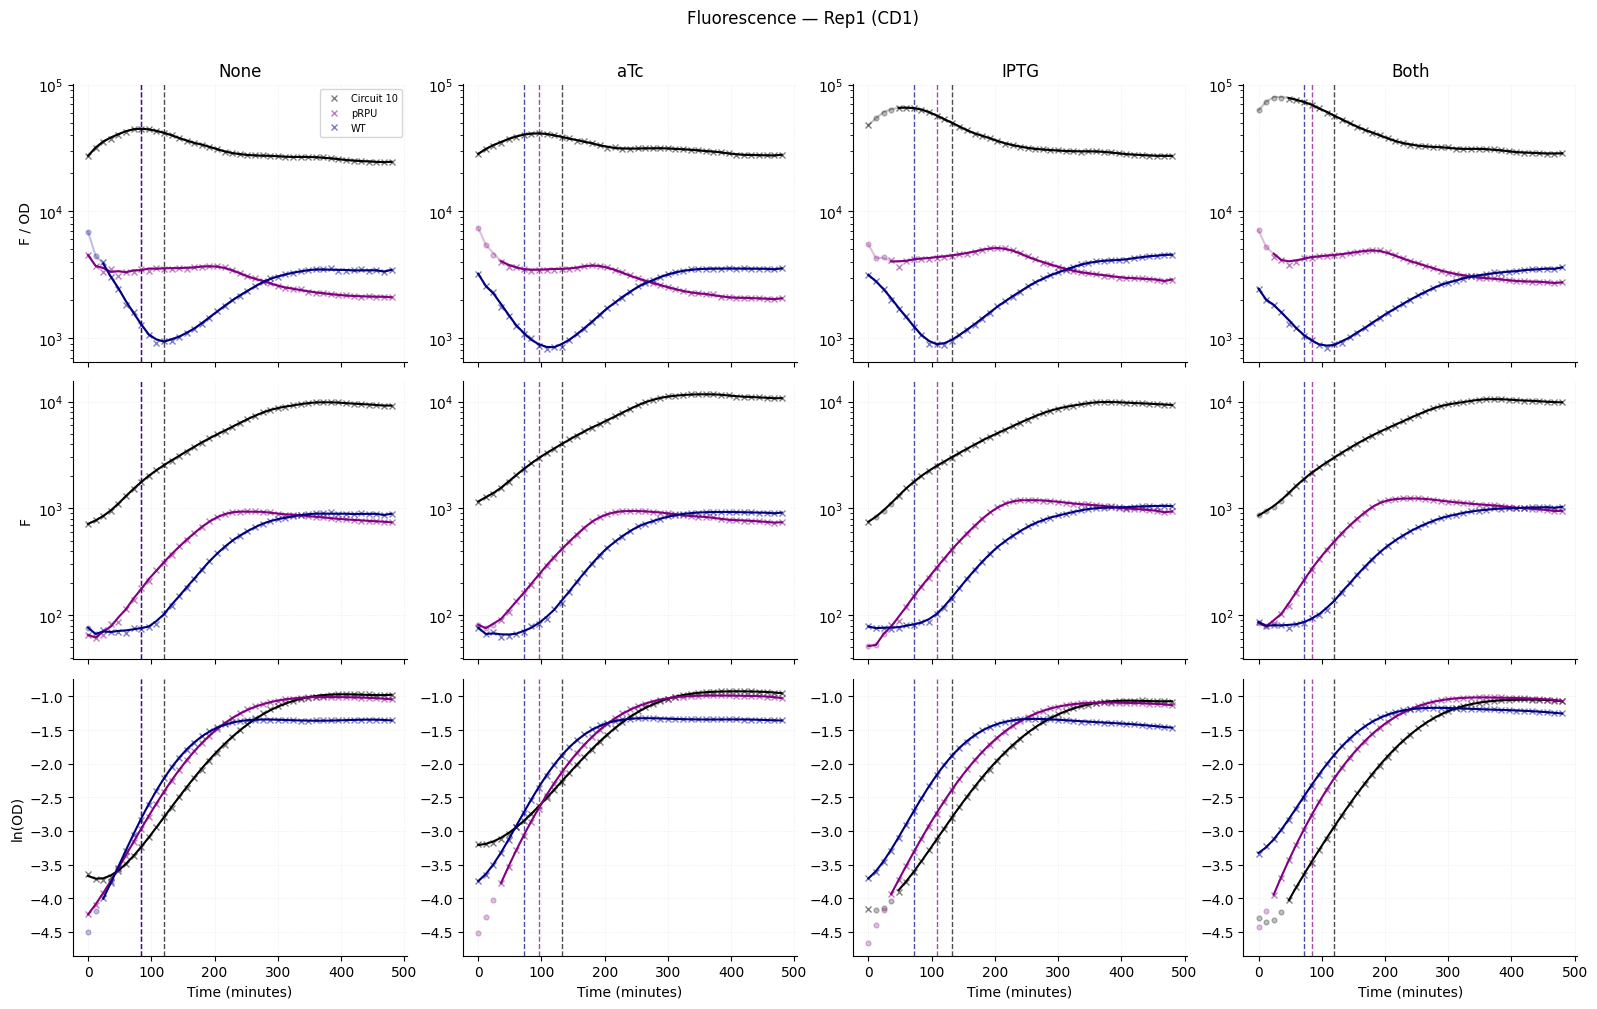

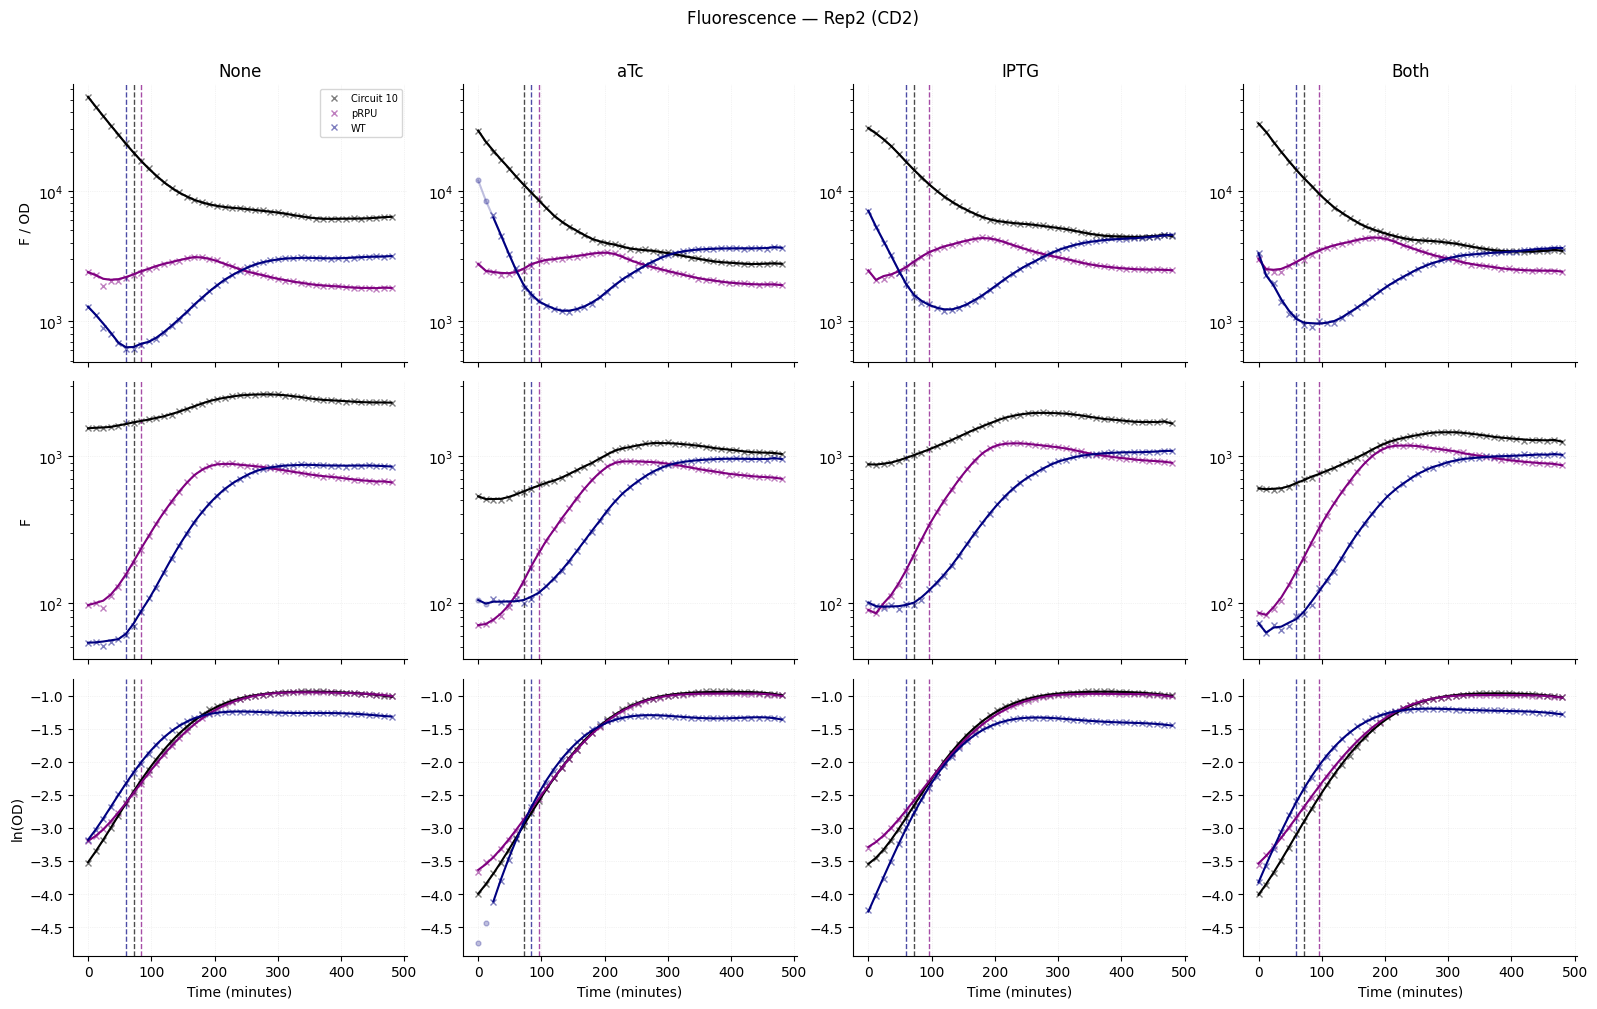

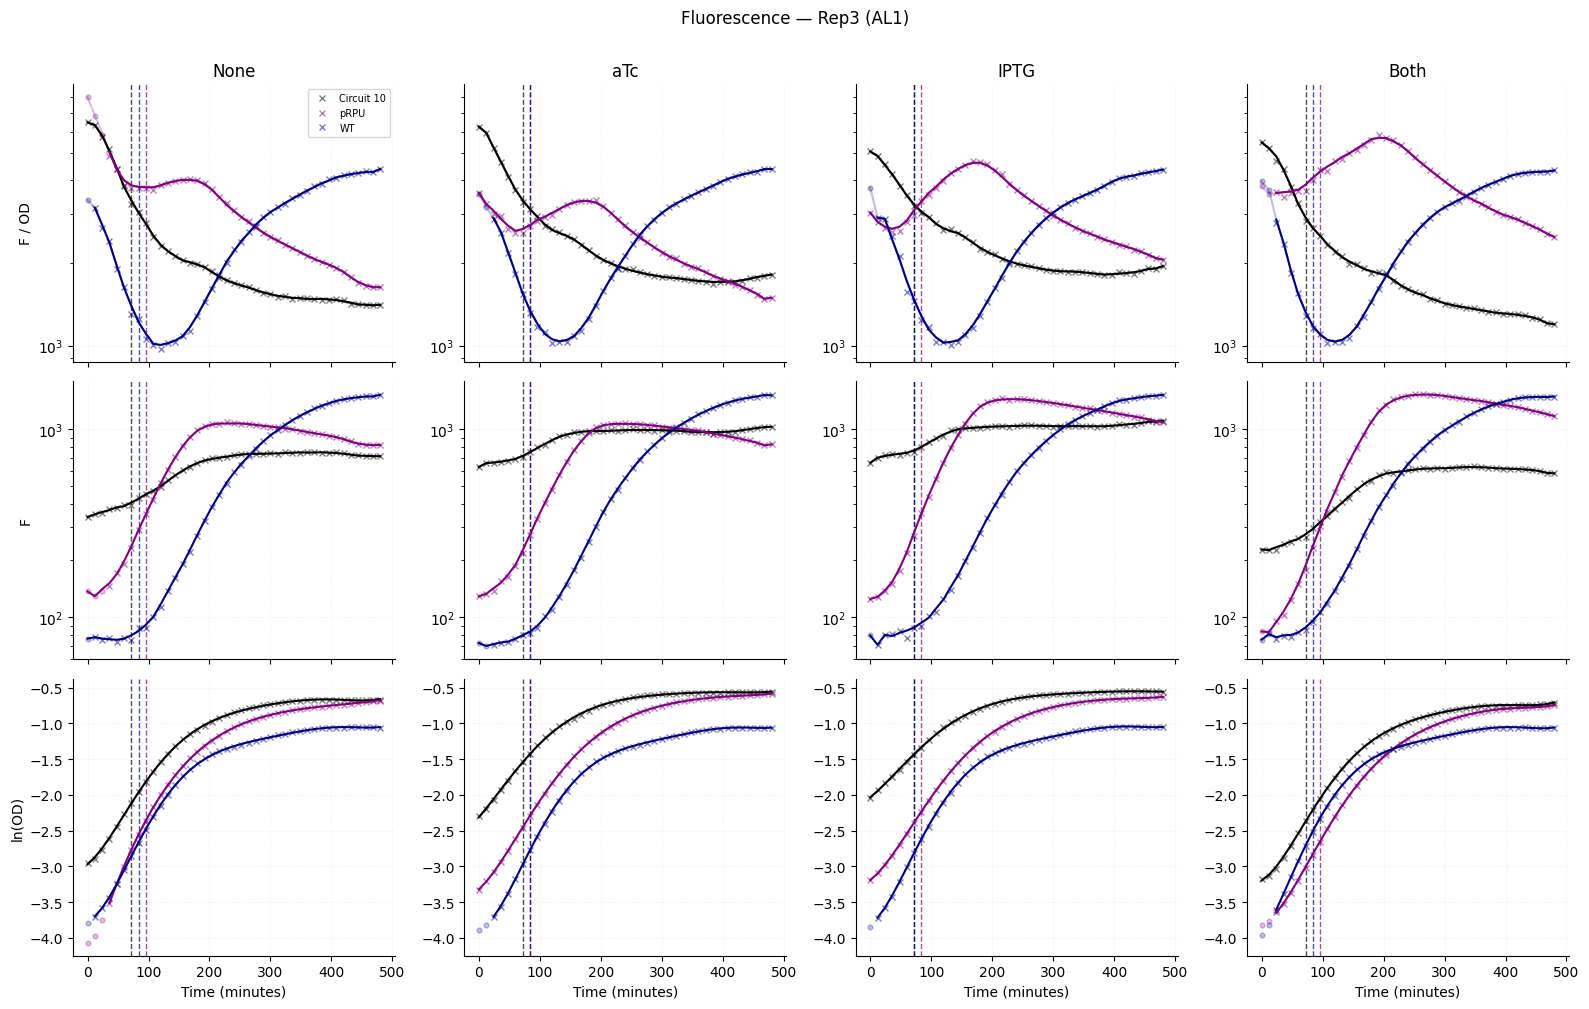

In [10]:
# Per-replicate 3x4 grid: F/OD, F and ln(OD) down, conditions across

for rep in REPLICATES:
    tag = rep["tag"]
    fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True)
    for row in range(3):
        for ax in axes[row, 1:]:
            ax.sharey(axes[row, 0])

    for well in range(4):
        ax_ratio, ax_fl, ax_od = axes[0, well], axes[1, well], axes[2, well]
        for name, (wells, colour) in GROUPS.items():
            above = above_floor[name][tag][well]
            od_well = biomass[name][tag][well]
            fl_well = fl_no_bg[name][tag][well]
            with np.errstate(invalid="ignore", divide="ignore"):
                ratio = fl_well / od_well
                ln_od = np.log(od_well)

            for ax, values, smooth in (
                (ax_ratio, ratio, ratio),
                (ax_fl, fl_well, fl_well),
                (ax_od, ln_od, ln_od_fit[name][tag][well]),
            ):
                ax.plot(t_minutes[tag][above], values[above], "x",
                        color=colour, ms=4, alpha=0.5, zorder=2, label=name)
                ax.plot(t_minutes[tag][~above], values[~above], "o",
                        color=colour, ms=3.5, alpha=0.25, zorder=1)
                # Below-floor F/OD is faded
                if ax is ax_ratio:
                    ax.plot(t_minutes[tag], smooth,
                            color=colour, lw=1.5, alpha=0.25, zorder=3)
                    ax.plot(t_minutes[tag], np.where(above, smooth, np.nan),
                            color=colour, lw=1.5, zorder=4)
                else:
                    ax.plot(t_minutes[tag], smooth, color=colour, lw=1.5, zorder=3)
                ax.axvline(t_sampled[name][tag][well], color=colour, ls="--",
                           lw=1, alpha=0.7)

        ax_ratio.set_yscale("log")
        ax_fl.set_yscale("log")
        ax_ratio.set_title(rep["cond_labels"][well])
        ax_od.set_xlabel("Time (minutes)")
        for ax in (ax_ratio, ax_fl, ax_od):
            ax.grid(True, alpha=0.3, linewidth=0.5, ls=":")
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
        if well == 0:
            ax_ratio.set_ylabel("F / OD")
            ax_fl.set_ylabel("F")
            ax_od.set_ylabel("ln(OD)")
            ax_ratio.legend(fontsize=7)

    fig.suptitle(f"Fluorescence — {tag} ({rep['label']})", y=1.005)
    plt.tight_layout()
    plt.show()


## All Circuits


In [11]:
def plot_fl_page(group):
    """One PDF page for a group: three (F/OD, F, ln(OD)) row-triples, one per replicate."""
    page_groups = {name: ALL_GROUPS[name] for name in (group, "pRPU", "WT")}

    figure, axes = plt.subplots(9, 4, figsize=(16, 27), sharex=True)
    for row in range(9):
        for ax in axes[row, 1:]:
            ax.sharey(axes[row, 0])

    for rep_i, rep in enumerate(REPLICATES):
        tag = rep["tag"]
        for well in range(4):
            ax_ratio = axes[3 * rep_i, well]
            ax_fl = axes[3 * rep_i + 1, well]
            ax_od = axes[3 * rep_i + 2, well]
            for name, (wells, colour) in page_groups.items():
                above = above_floor[name][tag][well]
                od_well = biomass[name][tag][well]
                fl_well = fl_no_bg[name][tag][well]
                with np.errstate(invalid="ignore", divide="ignore"):
                    ratio = fl_well / od_well
                    ln_od = np.log(od_well)

                for ax, values, smooth in (
                    (ax_ratio, ratio, ratio),
                    (ax_fl, fl_well, fl_well),
                    (ax_od, ln_od, ln_od_fit[name][tag][well]),
                ):
                    ax.plot(t_minutes[tag][above], values[above], "x",
                            color=colour, ms=4, alpha=0.5, zorder=2, label=name)
                    ax.plot(t_minutes[tag][~above], values[~above], "o",
                            color=colour, ms=3.5, alpha=0.25, zorder=1)
                    # Below-floor F/OD is faded
                    if ax is ax_ratio:
                        ax.plot(t_minutes[tag], smooth,
                                color=colour, lw=1.5, alpha=0.25, zorder=3)
                        ax.plot(t_minutes[tag], np.where(above, smooth, np.nan),
                                color=colour, lw=1.5, zorder=4)
                    else:
                        ax.plot(t_minutes[tag], smooth, color=colour, lw=1.5, zorder=3)
                    ax.axvline(t_sampled[name][tag][well], color=colour, ls="--",
                               lw=1, alpha=0.7)

            ax_ratio.set_yscale("log")
            ax_fl.set_yscale("log")
            if rep_i == 0:
                ax_ratio.set_title(rep["cond_labels"][well])
            if rep_i == len(REPLICATES) - 1:
                ax_od.set_xlabel("Time (minutes)")
            for ax in (ax_ratio, ax_fl, ax_od):
                ax.grid(True, alpha=0.3, linewidth=0.5, ls=":")
                for spine in ("top", "right"):
                    ax.spines[spine].set_visible(False)
            if well == 0:
                ax_ratio.set_ylabel(f"{tag} ({rep['label']})\nF / OD")
                ax_fl.set_ylabel("F")
                ax_od.set_ylabel("ln(OD)")
                if rep_i == 0:
                    ax_ratio.legend(fontsize=7)

    figure.suptitle(f"{group} — fluorescence", y=0.997)
    figure.subplots_adjust(left=0.05, right=0.99, top=0.97, bottom=0.02,
                           hspace=0.15, wspace=0.12)
    return figure


In [12]:
import time
from matplotlib.backends.backend_pdf import PdfPages

if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the per-circuit fluorescence PDF")
else:
    path = OUT_DIR / "analyse_pr_fl.pdf"
    started = time.perf_counter()
    with PdfPages(path) as pdf:
        # pL2 gets a page of its own
        groups = [f"Circuit {circuit}" for circuit in range(1, 93)] + ["pL2", "WT"]
        for group in groups:
            figure = plot_fl_page(group)
            pdf.savefig(figure, dpi=PDF_DPI)
            plt.close(figure)
    print(f"{path}: {len(groups)} pages, {time.perf_counter() - started:.0f}s, "
          f"{path.stat().st_size / 1e6:.1f} MB")


GENERATE_PDF is False: skipping the per-circuit fluorescence PDF
